# HMOG: histogram of time gaps between sessions

This notebook visualizes the **time gap between consecutive sessions of the same user**.

The gap is defined in the same way as in `hmog_raw_study.py`:

\[
\text{gap} = \text{start of current session} - \text{end of previous session}
\]

Sessions are ordered chronologically **within each subject**. Therefore, the first session of every subject has no preceding gap and is excluded from the histogram.

You can either:

1. load a previously generated `sessions.csv`, which is much faster, or
2. build the session statistics directly from the raw HMOG CSV files by reusing `hmog_raw_study.py`.


In [1]:
from pathlib import Path
import importlib.util

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)


## Configuration

If you already ran `hmog_raw_study.py`, point `SESSIONS_CSV` to the resulting `sessions.csv`.

Otherwise, set `SESSIONS_CSV = None`, set `DATA_ROOT` to the raw HMOG dataset directory, and make sure `HELPER_SCRIPT` points to `hmog_raw_study.py`.


In [8]:
# --- Choose the data source ---

# Fastest option: use the sessions.csv previously generated by hmog_raw_study.py.
SESSIONS_CSV = Path("hmog_raw_stats/sessions.csv")

# If SESSIONS_CSV does not exist, the notebook can build the statistics
# directly from the raw dataset using hmog_raw_study.py.
DATA_ROOT = Path("input_data/hmog_unarchived")
HELPER_SCRIPT = Path("hmog_raw_study.py")

# Histogram settings
GAP_UNIT = "days"       # "minutes", "hours", or "days"
BINS = 30               # integer number of histogram bins
EXCLUDE_NEGATIVE_GAPS = True


## Load or build the session DataFrame

The resulting `sessions` DataFrame contains one row per session and includes:

- `session_start`
- `session_end`
- `previous_session_end`
- `gap_from_previous_session_minutes`
- `gap_from_previous_session_hours`
- `gap_from_previous_session_days`


In [3]:
def load_hmog_helper(path: Path):
    path = path.expanduser().resolve()
    if not path.exists():
        raise FileNotFoundError(
            f"Could not find {path}. Put hmog_raw_study.py next to this notebook "
            "or change HELPER_SCRIPT."
        )

    spec = importlib.util.spec_from_file_location("hmog_raw_study", path)
    module = importlib.util.module_from_spec(spec)
    assert spec.loader is not None
    spec.loader.exec_module(module)
    return module


if SESSIONS_CSV is not None and SESSIONS_CSV.expanduser().exists():
    print(f"Loading precomputed session statistics from: {SESSIONS_CSV}")
    sessions = pd.read_csv(
        SESSIONS_CSV,
        parse_dates=["session_start", "session_end", "previous_session_end"],
    )
else:
    print("Precomputed sessions.csv was not found; building statistics from the raw HMOG data.")
    hmog = load_hmog_helper(HELPER_SCRIPT)
    stats = hmog.build_dataset_statistics(DATA_ROOT, verbose=True)
    sessions = stats["sessions"].copy()

print(f"Loaded {len(sessions):,} sessions from {sessions['subject_id'].nunique():,} subjects.")
sessions.head()


Loading precomputed session statistics from: hmog_raw_stats\sessions.csv
Loaded 2,398 sessions from 100 subjects.


,subject_id,session_number,task_id,task,condition,session_start,session_end,session_span_seconds,session_span_minutes,active_duration_seconds,active_duration_minutes,number_of_activities,written_text_combined,written_text_chars,written_text_chars_no_whitespace,written_text_words,key_down_events,key_up_events,raw_touch_rows,one_finger_gesture_rows,distinct_taps,pinch_gesture_rows,distinct_pinches,scroll_gesture_rows,distinct_scrolls,stroke_gesture_rows,gesture_event_rows_total,distinct_gestures_total,accelerometer_rows,gyroscope_rows,magnetometer_rows,motion_sensor_rows_total,session_dir,previous_session_end,gap_from_previous_session_seconds,gap_from_previous_session_minutes,gap_from_previous_session_hours,gap_from_previous_session_days
0,100669,1,7,reading,sitting,2014-03-31 00:36:53.027,2014-03-31 00:49:34.209,761.182,12.686367,732.248,12.204133,8,NaN,0,0,0,0,0,6966,19,10,0,0,5134,189,94,5247,293,76855,76851,76855,230561,C:\Users\Vadym\PycharmProjects\multimodal-beha...,NaT,NaN,NaN,NaN,NaN
1,100669,2,21,writing,sitting,2014-03-31 00:50:39.138,2014-03-31 01:08:51.055,1091.917,18.198617,1091.836,18.197267,3,Question: What do you like/dislike about publi...,1227,1017,211,843,851,3968,2102,855,0,0,14,0,9,2125,864,109042,109061,109062,327165,C:\Users\Vadym\PycharmProjects\multimodal-beha...,2014-03-31 00:49:34.209,64.929,1.082150,0.018036,0.000751
2,100669,3,15,writing,sitting,2014-03-31 01:09:54.492,2014-03-31 01:25:42.668,948.176,15.802933,948.103,15.801717,3,Question: Explain to a child how to do a task ...,1052,863,190,825,837,4035,2134,840,0,0,14,0,11,2159,851,94696,94701,94702,284099,C:\Users\Vadym\PycharmProjects\multimodal-beha...,2014-03-31 01:08:51.055,63.437,1.057283,0.017621,0.000734
3,100669,4,2,reading,walking,2014-03-31 01:26:32.637,2014-03-31 01:35:04.093,511.456,8.524267,458.992,7.649867,6,NaN,0,0,0,0,0,2516,12,6,0,0,1806,81,41,1859,128,51810,51818,51821,155449,C:\Users\Vadym\PycharmProjects\multimodal-beha...,2014-03-31 01:25:42.668,49.969,0.832817,0.013880,0.000578
4,100669,5,6,map,walking,2014-04-01 00:05:43.294,2014-04-01 00:11:54.353,371.059,6.184317,371.004,6.183400,6,NaN,0,0,0,0,0,7624,19,9,1992,56,2167,126,62,4240,253,36940,36858,36861,110659,C:\Users\Vadym\PycharmProjects\multimodal-beha...,2014-03-31 01:35:04.093,81039.201,1350.653350,22.510889,0.937954


## Inspect the chronological session gaps

This table is useful for checking that the interval calculation makes sense before plotting the distribution.


In [7]:
gap_columns = [
    "subject_id",
    "session_number",
    "session_start",
    "session_end",
    "previous_session_end",
    "gap_from_previous_session_hours",
    "gap_from_previous_session_days",
]

session_gaps = (
    sessions.loc[sessions["previous_session_end"].notna(), gap_columns]
    .sort_values(["subject_id", "session_start"])
    .reset_index(drop=True)
)

session_gaps.head(25)


,subject_id,session_number,session_start,session_end,previous_session_end,gap_from_previous_session_hours,gap_from_previous_session_days
0,100669,2,2014-03-31 00:50:39.138,2014-03-31 01:08:51.055,2014-03-31 00:49:34.209,0.018036,0.000751
1,100669,3,2014-03-31 01:09:54.492,2014-03-31 01:25:42.668,2014-03-31 01:08:51.055,0.017621,0.000734
2,100669,4,2014-03-31 01:26:32.637,2014-03-31 01:35:04.093,2014-03-31 01:25:42.668,0.013880,0.000578
3,100669,5,2014-04-01 00:05:43.294,2014-04-01 00:11:54.353,2014-03-31 01:35:04.093,22.510889,0.937954
4,100669,6,2014-04-01 00:12:40.955,2014-04-01 00:23:02.993,2014-04-01 00:11:54.353,0.012945,0.000539
5,100669,7,2014-04-01 00:24:03.382,2014-04-01 00:33:38.657,2014-04-01 00:23:02.993,0.016775,0.000699
6,100669,8,2014-04-01 00:34:31.456,2014-04-01 00:50:42.556,2014-04-01 00:33:38.657,0.014666,0.000611
7,100669,9,2014-04-01 23:38:46.444,2014-04-01 23:55:18.464,2014-04-01 00:50:42.556,22.801080,0.950045
8,100669,10,2014-04-01 23:55:50.200,2014-04-01 23:59:59.456,2014-04-01 23:55:18.464,0.008816,0.000367
9,100669,11,2014-04-02 00:00:23.654,2014-04-02 00:11:05.423,2014-04-01 23:59:59.456,0.006722,0.000280


## Check for missing or negative intervals

A negative value would mean that the recorded current session started before the previous session ended. Such values are worth inspecting rather than silently treating them as ordinary gaps.


In [8]:
gap_column = f"gap_from_previous_session_{GAP_UNIT}"

if gap_column not in sessions.columns:
    raise ValueError(
        f"Unknown GAP_UNIT={GAP_UNIT!r}. Use 'minutes', 'hours', or 'days'."
    )

all_gaps = sessions[gap_column].dropna()

print(f"Gap unit: {GAP_UNIT}")
print(f"Number of inter-session gaps: {len(all_gaps):,}")
print(f"Missing gaps (normally the first session of each user): {sessions[gap_column].isna().sum():,}")
print(f"Negative gaps: {(all_gaps < 0).sum():,}")

if (all_gaps < 0).any():
    display(
        sessions.loc[
            sessions[gap_column] < 0,
            [
                "subject_id",
                "session_number",
                "session_start",
                "session_end",
                "previous_session_end",
                gap_column,
            ],
        ].sort_values(gap_column)
    )


Gap unit: days
Number of inter-session gaps: 2,298
Missing gaps (normally the first session of each user): 100
Negative gaps: 0


## Summary statistics

The median and quartiles are especially useful here because inter-session gaps can be strongly right-skewed if some subjects returned days or weeks later.


In [9]:
gaps = all_gaps.copy()

if EXCLUDE_NEGATIVE_GAPS:
    gaps = gaps[gaps >= 0]

gap_summary = gaps.describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

gap_summary


count    2298.000000
mean        0.284238
std         0.742931
min         0.000129
10%         0.000251
25%         0.000378
50%         0.000590
75%         0.002043
90%         0.972832
95%         0.986208
99%         3.977863
max         8.904030
Name: gap_from_previous_session_days, dtype: float64

## Histogram of inter-session gaps


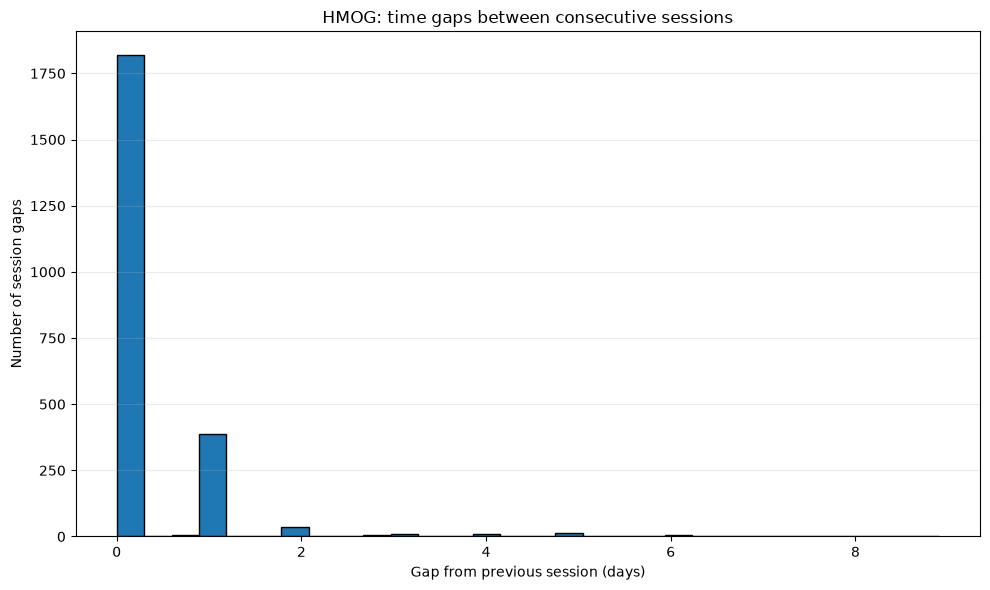

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(gaps, bins=BINS, edgecolor="black")

ax.set_title("HMOG: time gaps between consecutive sessions")
ax.set_xlabel(f"Gap from previous session ({GAP_UNIT})")
ax.set_ylabel("Number of session gaps")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


## Optional: focus on the central part of the distribution

If a few very long gaps compress most observations into the left edge of the main histogram, use a percentile cutoff for visualization only. This does **not** modify the underlying `sessions` DataFrame.


Showing gaps up to the 95% percentile: 0.986 days


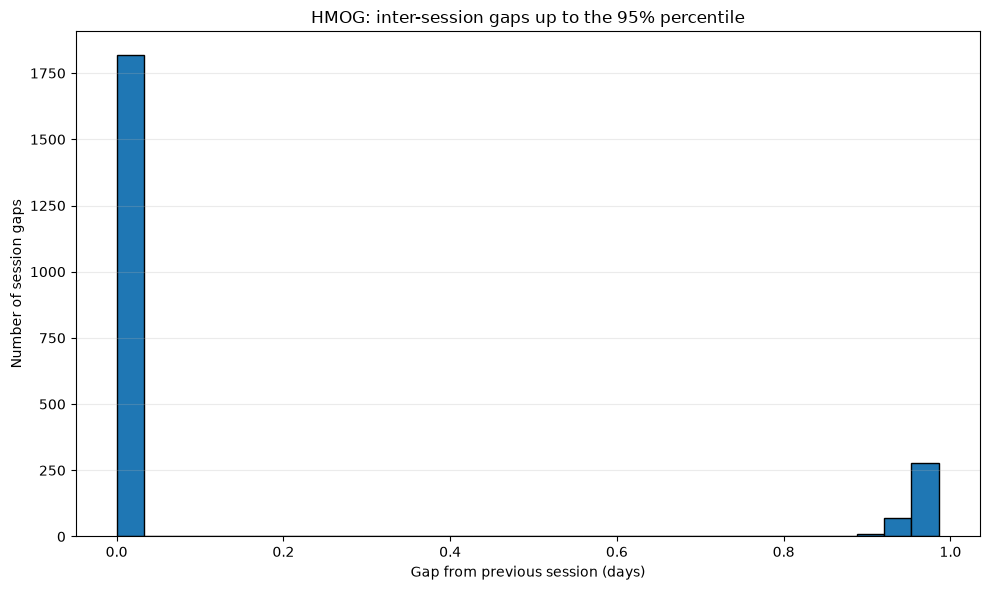

In [9]:
UPPER_PERCENTILE = 0.95

upper = gaps.quantile(UPPER_PERCENTILE)
central_gaps = gaps[gaps <= upper]

print(
    f"Showing gaps up to the {UPPER_PERCENTILE:.0%} percentile: "
    f"{upper:.3f} {GAP_UNIT}"
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(central_gaps, bins=BINS, edgecolor="black")

ax.set_title(
    f"HMOG: inter-session gaps up to the {UPPER_PERCENTILE:.0%} percentile"
)
ax.set_xlabel(f"Gap from previous session ({GAP_UNIT})")
ax.set_ylabel("Number of session gaps")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


## Optional: inspect the longest gaps


In [10]:
sessions.loc[
    sessions[gap_column].notna(),
    [
        "subject_id",
        "session_number",
        "session_start",
        "previous_session_end",
        gap_column,
    ],
].sort_values(gap_column, ascending=False).head(20)


,subject_id,session_number,session_start,previous_session_end,gap_from_previous_session_days
2334,986737,9,2014-06-05 21:58:05.425,2014-05-28 00:16:17.258,8.904030
1842,856401,21,2014-05-04 23:47:24.126,2014-04-28 00:26:25.258,6.972904
1962,872895,18,2014-05-04 23:47:20.786,2014-04-28 00:34:17.753,6.967396
1243,675397,21,2014-06-03 23:00:59.702,2014-05-28 22:21:51.861,6.027174
2187,937904,6,2014-04-16 22:56:15.392,2014-04-10 22:28:31.140,6.019262
2026,892687,13,2014-04-16 23:28:08.748,2014-04-10 23:42:45.809,5.989849
895,539502,9,2014-06-09 22:00:30.168,2014-06-03 22:29:49.628,5.979636
1810,856302,13,2014-04-16 23:05:30.488,2014-04-10 23:58:26.468,5.963241
1147,621276,21,2014-04-24 00:41:16.874,2014-04-19 00:09:45.221,5.021894
1381,733162,15,2014-05-28 01:06:54.703,2014-05-23 00:58:19.487,5.005963


Number of gaps > 10 minutes: 494


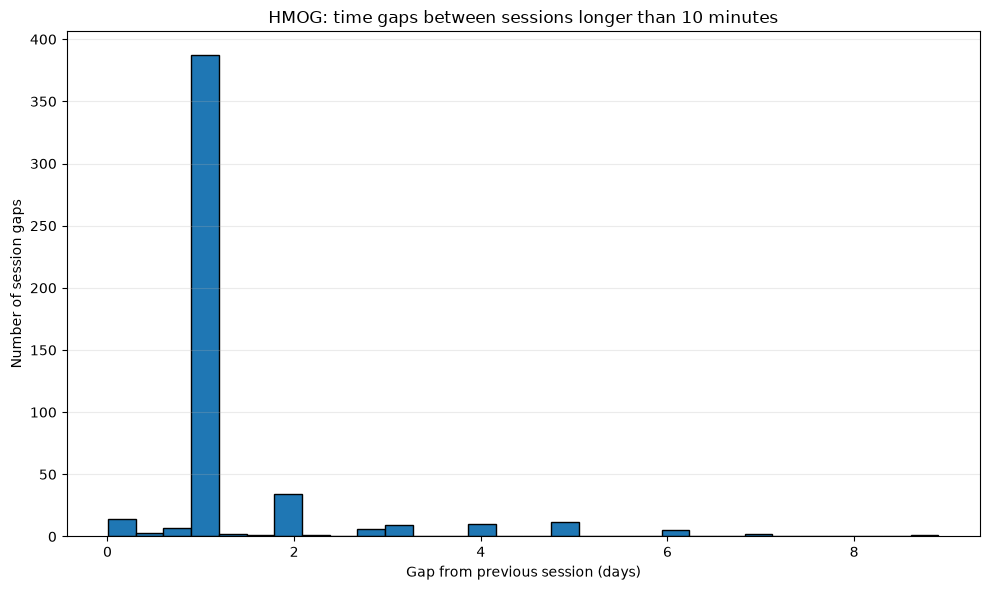

In [23]:
# Histogram of inter-session gaps longer than 10 minutes

gap_column = f"gap_from_previous_session_{GAP_UNIT}"

# Keep only valid gaps longer than 10 minutes
filtered = sessions.loc[
    sessions["gap_from_previous_session_minutes"] > 10,
    gap_column
].dropna()

print(f"Number of gaps > 10 minutes: {len(filtered):,}")

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(filtered, bins=BINS, edgecolor="black")

ax.set_title("HMOG: time gaps between sessions longer than 10 minutes")
ax.set_xlabel(f"Gap from previous session ({GAP_UNIT})")
ax.set_ylabel("Number of session gaps")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Total users: 100
Users with at least one gap > 1 days: 67
Percentage: 67.0%


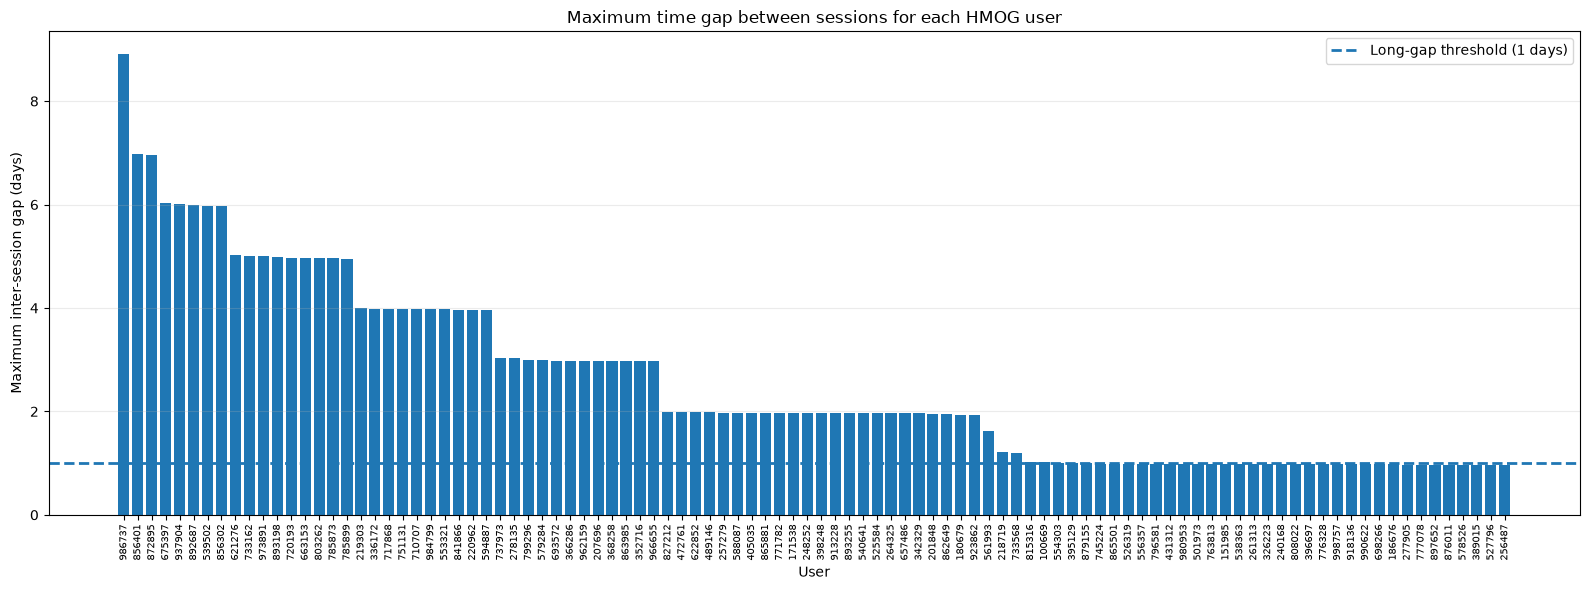

In [19]:
# Maximum inter-session gap per user

# Unit used in the chart
UNIT = "days"  # "minutes", "hours", or "days"

# Define what you consider a "long" gap
LONG_GAP_THRESHOLD = 1  # e.g. 1 day

gap_column = f"gap_from_previous_session_{UNIT}"

# Maximum valid time gap observed for each user
max_gap_per_user = (
    sessions.loc[sessions[gap_column] >= 0]
    .groupby("subject_id")[gap_column]
    .max()
    .sort_values(ascending=False)
)

# How many users had at least one long gap?
users_with_long_gap = (max_gap_per_user > LONG_GAP_THRESHOLD).sum()

print(f"Total users: {len(max_gap_per_user)}")
print(
    f"Users with at least one gap > {LONG_GAP_THRESHOLD} {UNIT}: "
    f"{users_with_long_gap}"
)
print(
    f"Percentage: "
    f"{100 * users_with_long_gap / len(max_gap_per_user):.1f}%"
)

# Plot
fig, ax = plt.subplots(figsize=(16, 6))

ax.bar(
    range(len(max_gap_per_user)),
    max_gap_per_user.values
)

# Threshold line
ax.axhline(
    LONG_GAP_THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=f"Long-gap threshold ({LONG_GAP_THRESHOLD} {UNIT})"
)

ax.set_title("Maximum time gap between sessions for each HMOG user")
ax.set_xlabel("User")
ax.set_ylabel(f"Maximum inter-session gap ({UNIT})")

ax.set_xticks(range(len(max_gap_per_user)))
ax.set_xticklabels(
    max_gap_per_user.index.astype(str),
    rotation=90,
    fontsize=7
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [24]:
# Group consecutive sessions with gaps < 10 minutes,
# then show the gaps between groups in human-readable form.

import pandas as pd

GROUP_GAP_THRESHOLD_MINUTES = 10


def format_duration_minutes(minutes):
    """Convert minutes to a compact human-readable duration."""
    if pd.isna(minutes):
        return "—"

    total_minutes = int(round(minutes))

    days = total_minutes // (24 * 60)
    remaining = total_minutes % (24 * 60)

    hours = remaining // 60
    mins = remaining % 60

    parts = []

    if days:
        parts.append(f"{days} d")
    if hours:
        parts.append(f"{hours} h")
    if mins or not parts:
        parts.append(f"{mins} m")

    return " ".join(parts)


# Work on a copy and sort sessions chronologically for each user
sessions_grouped = (
    sessions.copy()
    .sort_values(["subject_id", "session_start"])
    .reset_index(drop=True)
)


# A session starts a new group when:
# 1. it is the first session of a user, or
# 2. the gap from the previous session is >= 10 minutes
sessions_grouped["starts_new_group"] = (
    sessions_grouped["gap_from_previous_session_minutes"].isna()
    |
    (
        sessions_grouped["gap_from_previous_session_minutes"]
        >= GROUP_GAP_THRESHOLD_MINUTES
    )
)


# Number groups independently for every user
sessions_grouped["group_number"] = (
    sessions_grouped
    .groupby("subject_id")["starts_new_group"]
    .cumsum()
    .astype(int)
)


# Build one row per group
group_rows = []

for (subject_id, group_number), group in sessions_grouped.groupby(
    ["subject_id", "group_number"],
    sort=True
):
    group = group.sort_values("session_start")

    first_session = group.iloc[0]
    last_session = group.iloc[-1]

    # Make task names slightly more readable
    session_details = []

    for _, row in group.iterrows():
        task = str(row["task"]).lower()

        if task == "map":
            task = "navigating"

        session_details.append(
            f"{int(row['session_number'])} ({task})"
        )

    gap_minutes = first_session["gap_from_previous_session_minutes"]

    group_rows.append({
        "subject_id": subject_id,
        "group_number": group_number,
        "group_start": first_session["session_start"],
        "group_end": last_session["session_end"],
        "number_of_sessions": len(group),
        "sessions": session_details,
        "gap_from_previous_group_minutes": gap_minutes,
        "gap_from_previous_group": format_duration_minutes(gap_minutes),
    })


session_groups = (
    pd.DataFrame(group_rows)
    .sort_values(["subject_id", "group_number"])
    .reset_index(drop=True)
)


# Display a separate table for every user, sorted by user ID
for subject_id in sorted(session_groups["subject_id"].unique()):

    user_groups = (
        session_groups[
            session_groups["subject_id"] == subject_id
        ]
        .sort_values("group_number")
        .copy()
    )

    print("\n" + "=" * 100)
    print(f"USER {subject_id}")
    print(
        f"Number of session groups: {len(user_groups)} "
        f"(sessions are grouped when gaps are < "
        f"{GROUP_GAP_THRESHOLD_MINUTES} minutes)"
    )
    print("=" * 100)

    display(
        user_groups[
            [
                "group_number",
                "sessions",
                "gap_from_previous_group",
                "group_start",
                "group_end",
            ]
        ].reset_index(drop=True)
    )


USER 100669
Number of session groups: 6 (sessions are grouped when gaps are < 10 minutes)


,group_number,sessions,gap_from_previous_group,group_start,group_end
0,1,"[1 (reading), 2 (writing), 3 (writing), 4 (rea...",—,2014-03-31 00:36:53.027,2014-03-31 01:35:04.093
1,2,"[5 (navigating), 6 (reading), 7 (reading), 8 (...",22 h 31 m,2014-04-01 00:05:43.294,2014-04-01 00:50:42.556
2,3,"[9 (writing), 10 (navigating), 11 (reading), 1...",22 h 48 m,2014-04-01 23:38:46.444,2014-04-02 00:18:52.845
3,4,"[13 (navigating), 14 (reading), 15 (reading), ...",23 h 13 m,2014-04-02 23:31:28.535,2014-04-03 00:00:19.781
4,5,"[17 (navigating), 18 (writing), 19 (writing), ...",1 d 27 m,2014-04-04 00:27:39.509,2014-04-04 01:10:55.175
5,6,"[21 (navigating), 22 (writing), 23 (reading), ...",22 h 18 m,2014-04-04 23:28:41.410,2014-04-05 00:17:32.482



USER 151985
Number of session groups: 6 (sessions are grouped when gaps are < 10 minutes)


,group_number,sessions,gap_from_previous_group,group_start,group_end
0,1,"[2 (reading), 3 (writing), 1 (reading), 4 (wri...",—,2014-05-19 01:04:30.426,2014-05-19 02:00:19.292
1,2,"[5 (navigating), 6 (navigating), 7 (writing), ...",22 h 3 m,2014-05-20 00:03:27.913,2014-05-20 00:39:17.240
2,3,"[9 (writing), 10 (navigating), 11 (navigating)...",23 h 36 m,2014-05-21 00:15:45.747,2014-05-21 01:00:27.205
3,4,"[13 (navigating), 14 (reading), 15 (writing), ...",22 h 55 m,2014-05-21 23:54:57.891,2014-05-22 00:30:50.204
4,5,"[17 (navigating), 18 (reading), 19 (reading), ...",23 h 25 m,2014-05-22 23:56:18.765,2014-05-23 00:30:18.098
5,6,"[21 (writing), 22 (navigating), 23 (reading), ...",22 h 30 m,2014-05-23 23:00:31.335,2014-05-23 23:37:55.820



USER 171538
Number of session groups: 6 (sessions are grouped when gaps are < 10 minutes)


,group_number,sessions,gap_from_previous_group,group_start,group_end
0,1,"[1 (navigating), 2 (writing), 3 (writing), 4 (...",—,2014-04-22 23:31:44.150,2014-04-23 00:13:32.643
1,2,"[5 (writing), 6 (reading), 7 (reading), 8 (nav...",22 h 52 m,2014-04-23 23:05:57.845,2014-04-23 23:44:44.627
2,3,"[9 (reading), 10 (writing), 12 (reading), 13 (...",23 h 23 m,2014-04-24 23:07:41.227,2014-04-24 23:39:38.483
3,4,"[15 (reading), 18 (writing), 20 (writing), 21 ...",1 d 23 h 18 m,2014-04-26 22:57:58.405,2014-04-26 23:27:22.842
4,5,"[23 (reading), 24 (writing), 11 (navigating), ...",23 h 44 m,2014-04-27 23:11:34.495,2014-04-27 23:56:27.323
5,6,"[16 (navigating), 17 (navigating), 19 (navigat...",23 h 13 m,2014-04-28 23:09:00.874,2014-04-28 23:42:36.356


... (190 outputs left out)


USER 990622
Number of session groups: 5 (sessions are grouped when gaps are < 10 minutes)


,group_number,sessions,gap_from_previous_group,group_start,group_end
0,1,"[1 (navigating), 2 (writing), 3 (reading), 4 (...",—,2014-05-15 23:15:56.824,2014-05-15 23:55:48.507
1,2,"[5 (reading), 6 (reading), 7 (reading), 8 (wri...",23 h 15 m,2014-05-16 23:11:07.289,2014-05-16 23:49:56.605
2,3,"[10 (writing), 11 (writing), 12 (writing), 13 ...",23 h 25 m,2014-05-17 23:14:57.282,2014-05-17 23:59:54.055
3,4,"[15 (reading), 16 (writing), 17 (navigating), ...",22 h 58 m,2014-05-18 22:57:48.743,2014-05-18 23:41:32.012
4,5,"[20 (navigating), 21 (reading), 22 (navigating...",14 h 6 m,2014-05-19 13:47:24.016,2014-05-19 14:27:10.835



USER 998757
Number of session groups: 6 (sessions are grouped when gaps are < 10 minutes)


,group_number,sessions,gap_from_previous_group,group_start,group_end
0,1,"[1 (reading), 2 (reading), 3 (writing), 4 (rea...",—,2014-05-02 23:20:05.238,2014-05-02 23:52:43.288
1,2,"[5 (navigating), 6 (writing), 7 (reading), 8 (...",23 h 5 m,2014-05-03 22:57:38.553,2014-05-03 23:46:18.585
2,3,"[9 (navigating), 10 (navigating), 11 (writing)...",23 h 10 m,2014-05-04 22:56:24.990,2014-05-04 23:39:06.464
3,4,"[14 (reading), 15 (writing), 16 (writing), 17 ...",23 h 20 m,2014-05-05 22:59:22.849,2014-05-05 23:41:28.370
4,5,"[19 (reading), 20 (reading), 22 (writing), 23 ...",23 h 31 m,2014-05-06 23:12:45.439,2014-05-06 23:53:39.893
5,6,"[24 (navigating), 13 (navigating), 18 (navigat...",23 h 5 m,2014-05-07 22:58:42.015,2014-05-07 23:24:55.825


In [25]:
# Frequency of calendar-day pauses between consecutive occurrences
# of each task + condition pair, across all users.

import pandas as pd

df = sessions.copy()

# Ensure datetime
df["session_start"] = pd.to_datetime(df["session_start"])

# Normalize task names for readability
df["task_readable"] = (
    df["task"]
    .astype(str)
    .str.lower()
    .replace({
        "map": "navigating",
        "navigation": "navigating",
    })
)

df["condition_readable"] = df["condition"].astype(str).str.lower()

# e.g. "writing + sitting"
df["task_condition"] = (
    df["task_readable"] + " + " + df["condition_readable"]
)

# Sort chronologically within each user and task-condition pair
df = df.sort_values(
    ["subject_id", "task_condition", "session_start"]
).reset_index(drop=True)

# Previous occurrence of the SAME task-condition pair for the SAME user
df["previous_same_pair_start"] = (
    df.groupby(["subject_id", "task_condition"])["session_start"]
    .shift(1)
)

# Calendar dates
df["session_date"] = df["session_start"].dt.normalize()
df["previous_same_pair_date"] = (
    df["previous_same_pair_start"].dt.normalize()
)

# Calendar-day pause:
# 0 = same day
# 1 = next day
# 2 = two calendar days later
# etc.
df["pause_days"] = (
    df["session_date"] - df["previous_same_pair_date"]
).dt.days

# Remove the first occurrence of each pair for each user,
# because it has no previous occurrence to compare with.
pair_pauses = df.dropna(subset=["pause_days"]).copy()
pair_pauses["pause_days"] = pair_pauses["pause_days"].astype(int)


# ------------------------------------------------------------
# Frequency counts
# ------------------------------------------------------------

pause_frequency = (
    pair_pauses
    .groupby(["task_condition", "pause_days"])
    .size()
    .rename("frequency")
    .reset_index()
)

# Add percentage within each task-condition pair
pause_frequency["percentage"] = (
    pause_frequency["frequency"]
    / pause_frequency.groupby("task_condition")["frequency"].transform("sum")
    * 100
)


# ------------------------------------------------------------
# Pivot table: COUNTS
# ------------------------------------------------------------

frequency_table = (
    pause_frequency
    .pivot(
        index="task_condition",
        columns="pause_days",
        values="frequency"
    )
    .fillna(0)
    .astype(int)
)

# Ensure columns appear as 0 days, 1 day, 2 days, ...
frequency_table = frequency_table.reindex(
    sorted(frequency_table.columns),
    axis=1
)

frequency_table.columns = [
    f"{day} day" if day == 1 else f"{day} days"
    for day in frequency_table.columns
]


# ------------------------------------------------------------
# Pivot table: PERCENTAGES
# ------------------------------------------------------------

percentage_table = (
    pause_frequency
    .pivot(
        index="task_condition",
        columns="pause_days",
        values="percentage"
    )
    .fillna(0)
)

percentage_table = percentage_table.reindex(
    sorted(percentage_table.columns),
    axis=1
)

percentage_table.columns = [
    f"{day} day" if day == 1 else f"{day} days"
    for day in percentage_table.columns
]


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("FREQUENCY OF CALENDAR-DAY PAUSES")
print(
    "Each observation is the pause between two consecutive occurrences "
    "of the same task + condition pair for the same user."
)
display(frequency_table)

print("\nPERCENTAGE DISTRIBUTION WITHIN EACH TASK + CONDITION PAIR")
display(percentage_table.round(1))


# ------------------------------------------------------------
# Sanity check
# ------------------------------------------------------------

print("\nNUMBER OF PAUSE OBSERVATIONS PER PAIR")

observations_per_pair = (
    pair_pauses
    .groupby("task_condition")
    .size()
    .rename("number_of_pauses")
    .to_frame()
)

display(observations_per_pair)

FREQUENCY OF CALENDAR-DAY PAUSES
Each observation is the pause between two consecutive occurrences of the same task + condition pair for the same user.


,0 days,1 day,2 days,3 days,4 days,5 days,6 days,7 days,8 days,9 days,14 days
task_condition,,,,,,,,,,,
navigating + sitting,96,97,47,24,15,7,5,4,3,1,1
navigating + walking,103,96,42,20,8,11,9,6,1,3,0
reading + sitting,93,101,46,27,12,8,3,6,1,2,0
reading + walking,91,104,47,24,17,6,7,4,0,0,0
writing + sitting,82,107,48,25,17,9,7,3,1,0,1
writing + walking,75,125,44,28,8,6,6,4,4,0,0



PERCENTAGE DISTRIBUTION WITHIN EACH TASK + CONDITION PAIR


,0 days,1 day,2 days,3 days,4 days,5 days,6 days,7 days,8 days,9 days,14 days
task_condition,,,,,,,,,,,
navigating + sitting,32.0,32.3,15.7,8.0,5.0,2.3,1.7,1.3,1.0,0.3,0.3
navigating + walking,34.4,32.1,14.0,6.7,2.7,3.7,3.0,2.0,0.3,1.0,0.0
reading + sitting,31.1,33.8,15.4,9.0,4.0,2.7,1.0,2.0,0.3,0.7,0.0
reading + walking,30.3,34.7,15.7,8.0,5.7,2.0,2.3,1.3,0.0,0.0,0.0
writing + sitting,27.3,35.7,16.0,8.3,5.7,3.0,2.3,1.0,0.3,0.0,0.3
writing + walking,25.0,41.7,14.7,9.3,2.7,2.0,2.0,1.3,1.3,0.0,0.0



NUMBER OF PAUSE OBSERVATIONS PER PAIR


,number_of_pauses
task_condition,
navigating + sitting,300
navigating + walking,299
reading + sitting,299
reading + walking,300
writing + sitting,300
writing + walking,300


In [26]:
# Non-overlapping classification:
# For each task_condition, classify every user by the MAXIMUM number
# of sessions of that same task_condition they had on any one calendar day.

import pandas as pd

df = sessions.copy()

df["session_start"] = pd.to_datetime(df["session_start"])
df["session_date"] = df["session_start"].dt.date

# Normalize names
df["task_readable"] = (
    df["task"]
    .astype(str)
    .str.lower()
    .replace({
        "map": "navigating",
        "navigation": "navigating",
    })
)

df["condition_readable"] = (
    df["condition"]
    .astype(str)
    .str.lower()
)

df["task_condition"] = (
    df["task_readable"]
    + " + "
    + df["condition_readable"]
)

# Count how many sessions of each task_condition
# each user had on each calendar day
sessions_per_day = (
    df
    .groupby(
        ["subject_id", "task_condition", "session_date"]
    )
    .size()
    .rename("sessions_on_day")
    .reset_index()
)

# For each user and task_condition, find the maximum number
# observed on any single day
max_same_day = (
    sessions_per_day
    .groupby(
        ["subject_id", "task_condition"]
    )["sessions_on_day"]
    .max()
    .reset_index(name="max_sessions_same_day")
)

# Count users in each mutually exclusive category
max_same_day_counts = (
    max_same_day
    .groupby(
        ["task_condition", "max_sessions_same_day"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[1, 2, 3, 4], fill_value=0)
)

max_same_day_counts.columns = [
    "1 session max",
    "2 sessions max",
    "3 sessions max",
    "4 sessions max",
]

print(
    "USERS CLASSIFIED BY THE MAXIMUM NUMBER OF SAME "
    "TASK-CONDITION SESSIONS ON ONE DAY"
)

display(max_same_day_counts)

USERS CLASSIFIED BY THE MAXIMUM NUMBER OF SAME TASK-CONDITION SESSIONS ON ONE DAY


,1 session max,2 sessions max,3 sessions max,4 sessions max
task_condition,,,,
navigating + sitting,25,63,11,1
navigating + walking,19,69,11,1
reading + sitting,24,68,8,0
reading + walking,21,71,8,0
writing + sitting,30,63,7,0
writing + walking,36,60,4,0


In [13]:
# Logical gesture/event statistics per task + condition.
#
# Uses:
#   distinct_taps
#   distinct_pinches
#   distinct_scrolls
#
# and keeps:
#   raw_touch_rows
#   key_down_events + key_up_events
#   stroke_gesture_rows
#
# Statistics are calculated across sessions.

import pandas as pd

df = sessions.copy()

# ------------------------------------------------------------
# Readable task-condition names
# ------------------------------------------------------------

df["task_readable"] = (
    df["task"]
    .astype(str)
    .str.lower()
    .replace({
        "map": "navigating",
        "navigation": "navigating",
    })
)

df["condition_readable"] = (
    df["condition"]
    .astype(str)
    .str.lower()
)

df["task_condition"] = (
    df["task_readable"]
    + " + "
    + df["condition_readable"]
)

# ------------------------------------------------------------
# Logical/event count columns
# ------------------------------------------------------------

event_columns = {
    "Raw touch events": "raw_touch_rows",
    "Taps": "distinct_taps",
    "Key presses": "key_up_events",
    "Pinches": "distinct_pinches",
    "Scrolls": "distinct_scrolls",
    "Strokes": "stroke_gesture_rows",
}
# ------------------------------------------------------------
# Long-form table
# ------------------------------------------------------------

rows = []

for event_type, column in event_columns.items():

    temp = df[
        [
            "subject_id",
            "session_number",
            "task_condition",
            column,
        ]
    ].copy()

    temp = temp.rename(columns={column: "event_count"})
    temp["event_type"] = event_type

    rows.append(temp)

logical_event_counts = pd.concat(
    rows,
    ignore_index=True
)

logical_event_counts["event_count"] = (
    pd.to_numeric(
        logical_event_counts["event_count"],
        errors="coerce"
    )
    .fillna(0)
)

# ------------------------------------------------------------
# Statistics across sessions
# ------------------------------------------------------------

logical_event_stats = (
    logical_event_counts
    .groupby(
        ["task_condition", "event_type"]
    )["event_count"]
    .agg(
        total="sum",
        mean="mean",
        min="min",
        max="max",
        std="std",
        median="median",
        n_sessions="count",
    )
    .reset_index()
)

for column in ["total", "min", "max", "n_sessions"]:
    logical_event_stats[column] = (
        logical_event_stats[column].astype(int)
    )

for column in ["mean", "std", "median"]:
    logical_event_stats[column] = (
        logical_event_stats[column].round(2)
    )

# ------------------------------------------------------------
# Display one table per task_condition
# ------------------------------------------------------------

for task_condition in sorted(
    logical_event_stats["task_condition"].unique()
):

    print("\n" + "=" * 100)
    print(task_condition.upper())
    print("=" * 100)

    display(
        logical_event_stats[
            logical_event_stats["task_condition"]
            == task_condition
        ]
        .drop(columns="task_condition")
        .set_index("event_type")
    )

# Combined table
print("\n" + "=" * 100)
print("ALL TASK-CONDITIONS")
print("=" * 100)

display(
    logical_event_stats
    .set_index(["task_condition", "event_type"])
)


NAVIGATING + SITTING


,total,mean,min,max,std,median,n_sessions
event_type,,,,,,,
Key presses,0,0.00,0,0,0.00,0.0,400
Pinches,28857,72.14,0,304,38.68,67.0,400
Raw touch events,3785176,9462.94,1472,28586,4296.90,8572.0,400
Scrolls,65617,164.04,33,558,76.00,150.0,400
Strokes,27073,67.68,0,319,56.19,63.0,400
Taps,9818,24.54,2,180,41.25,7.0,400



NAVIGATING + WALKING


,total,mean,min,max,std,median,n_sessions
event_type,,,,,,,
Key presses,0,0.00,0,0,0.00,0.0,399
Pinches,33733,84.54,2,309,40.81,79.0,399
Raw touch events,4374703,10964.17,2200,31448,4426.74,10250.0,399
Scrolls,83169,208.44,57,504,81.64,196.0,399
Strokes,39474,98.93,0,318,63.59,76.0,399
Taps,9578,24.01,2,185,41.69,7.0,399



READING + SITTING


,total,mean,min,max,std,median,n_sessions
event_type,,,,,,,
Key presses,0,0.00,0,0,0.00,0.0,399
Pinches,70,0.18,0,9,1.01,0.0,399
Raw touch events,1083352,2715.17,30,13106,2307.33,1977.0,399
Scrolls,20991,52.61,1,218,37.74,41.0,399
Strokes,12026,30.14,0,168,24.50,24.0,399
Taps,3005,7.53,2,28,3.93,7.0,399


... (4 outputs left out)


WRITING + WALKING


,total,mean,min,max,std,median,n_sessions
event_type,,,,,,,
Key presses,449807,1124.52,613,3509,304.20,1056.0,400
Pinches,4,0.01,0,1,0.10,0.0,400
Raw touch events,565556,1413.89,12,14865,2726.16,85.0,400
Scrolls,0,0.00,0,0,0.00,0.0,400
Strokes,9670,24.18,0,168,28.87,13.0,400
Taps,449716,1124.29,613,3509,303.67,1052.5,400



ALL TASK-CONDITIONS


total      mean   min    max      std   median  n_sessions
task_condition       event_type                                                                    
navigating + sitting Key presses             0      0.00     0      0     0.00      0.0         400
                     Pinches             28857     72.14     0    304    38.68     67.0         400
                     Raw touch events  3785176   9462.94  1472  28586  4296.90   8572.0         400
                     Scrolls             65617    164.04    33    558    76.00    150.0         400
                     Strokes             27073     67.68     0    319    56.19     63.0         400
                     Taps                 9818     24.54     2    180    41.25      7.0         400
navigating + walking Key presses             0      0.00     0      0     0.00      0.0         399
                     Pinches             33733     84.54     2    309    40.81     79.0         399
                     Raw touch events  4374703  10964.17  2200  31448  4426.74  10250.0         399
                     Scrolls             83169    208.44    57    504    81.64    196.0         399
                     Strokes             39474     98.93     0    318    63.59     76.0         399
                     Taps                 9578     24.01     2    185    41.69      7.0         399
reading + sitting    Key presses             0      0.00     0      0     0.00      0.0         399
                     Pinches                70      0.18     0      9     1.01      0.0         399
                     Raw touch events  1083352   2715.17    30  13106  2307.33   1977.0         399
                     Scrolls             20991     52.61     1    218    37.74     41.0         399
                     Strokes             12026     30.14     0    168    24.50     24.0         399
                     Taps                 3005      7.53     2     28     3.93      7.0         399
reading + walking    Key presses             0      0.00     0      0     0.00      0.0         400
                     Pinches                59      0.15     0     10     0.81      0.0         400
                     Raw touch events   954222   2385.55    49  11899  1873.84   1921.0         400
                     Scrolls             20191     50.48     2    296    33.39     41.0         400
                     Strokes             11409     28.52     0    229    22.12     23.0         400
                     Taps                 2790      6.98     1     21     3.53      6.0         400
writing + sitting    Key presses        461990   1154.97   565   2382   283.08   1097.5         400
                     Pinches                 2      0.00     0      1     0.07      0.0         400
                     Raw touch events   573365   1433.41    10  11151  2811.08     76.5         400
                     Scrolls                 0      0.00     0      0     0.00      0.0         400
                     Strokes             10123     25.31     0    191    29.70     14.0         400
                     Taps               462039   1155.10   567   2382   282.73   1097.5         400
writing + walking    Key presses        449807   1124.52   613   3509   304.20   1056.0         400
                     Pinches                 4      0.01     0      1     0.10      0.0         400
                     Raw touch events   565556   1413.89    12  14865  2726.16     85.0         400
                     Scrolls                 0      0.00     0      0     0.00      0.0         400
                     Strokes              9670     24.18     0    168    28.87     13.0         400
                     Taps               449716   1124.29   613   3509   303.67   1052.5         400

In [14]:
counts = (
    sessions
    .groupby(["subject_id", "task", "condition"])
    .size()
    .reset_index(name="n_sessions")
)

display(
    counts[counts["n_sessions"] != 4]
    .sort_values(["subject_id", "task", "condition"])
)

,subject_id,task,condition,n_sessions
205,526319,map,walking,3
410,796581,reading,sitting,3


In [19]:
# Session-duration statistics per task + condition

import pandas as pd

df = sessions.copy()

# ------------------------------------------------------------
# Create readable task-condition names
# ------------------------------------------------------------

df["task_readable"] = (
    df["task"]
    .astype(str)
    .str.lower()
    .replace({
        "map": "navigating",
        "navigation": "navigating",
    })
)

df["condition_readable"] = (
    df["condition"]
    .astype(str)
    .str.lower()
)

df["task_condition"] = (
    df["task_readable"]
    + " + "
    + df["condition_readable"]
)


# ------------------------------------------------------------
# Duration formatter
# ------------------------------------------------------------

def format_minutes(minutes):
    """
    Format a duration given in minutes as 'X h Y m Z s'.
    """
    if pd.isna(minutes):
        return "—"

    total_seconds = int(round(minutes * 60))

    hours = total_seconds // 3600
    remaining = total_seconds % 3600

    mins = remaining // 60
    secs = remaining % 60

    result_str = f"{mins}m {secs}s"
    if hours:
        result_str = f"{hours}h {result_str}"
    return result_str


# ------------------------------------------------------------
# Calculate statistics
#
# session_span_minutes =
#     session_end - session_start
# ------------------------------------------------------------

duration_stats_raw = (
    df
    .groupby("task_condition")["session_span_minutes"]
    .agg(
        total="sum",
        mean="mean",
        min="min",
        max="max",
        std="std",
        median="median",
        n_sessions="count",
    )
)


# ------------------------------------------------------------
# Format duration columns
# ------------------------------------------------------------

duration_stats = duration_stats_raw.copy()

duration_columns = [
    "total",
    "mean",
    "min",
    "max",
    "std",
    "median",
]

for column in duration_columns:
    duration_stats[column] = (
        duration_stats[column]
        .apply(format_minutes)
    )

duration_stats["n_sessions"] = (
    duration_stats["n_sessions"]
    .astype(int)
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("SESSION DURATION STATISTICS BY TASK + CONDITION")

display(duration_stats)

SESSION DURATION STATISTICS BY TASK + CONDITION


,total,mean,min,max,std,median,n_sessions
task_condition,,,,,,,
navigating + sitting,39h 47m 18s,5m 58s,1m 37s,15m 9s,2m 31s,5m 26s,400
navigating + walking,48h 40m 5s,7m 19s,2m 43s,15m 14s,2m 24s,7m 4s,399
reading + sitting,48h 27m 48s,7m 17s,0m 42s,20m 32s,3m 3s,6m 54s,399
reading + walking,51h 6m 37s,7m 40s,0m 53s,20m 0s,2m 42s,7m 33s,400
writing + sitting,77h 48m 39s,11m 40s,3m 44s,30m 34s,4m 23s,10m 52s,400
writing + walking,76h 44m 18s,11m 31s,3m 14s,37m 28s,4m 44s,10m 30s,400


,subject_id,task_condition,total_minutes,total_raw_touch_events,n_sessions
0,100669,navigating + sitting,18.829317,28584,4
6,151985,navigating + sitting,18.930583,34311,4
12,171538,navigating + sitting,34.320750,67209,4
18,180679,navigating + sitting,14.742517,21873,4
24,186676,navigating + sitting,21.755033,37497,4
...,...,...,...,...,...
575,980953,writing + walking,44.090700,178,4
581,984799,writing + walking,27.823800,174,4
587,986737,writing + walking,38.948533,176,4
593,990622,writing + walking,31.035067,256,4


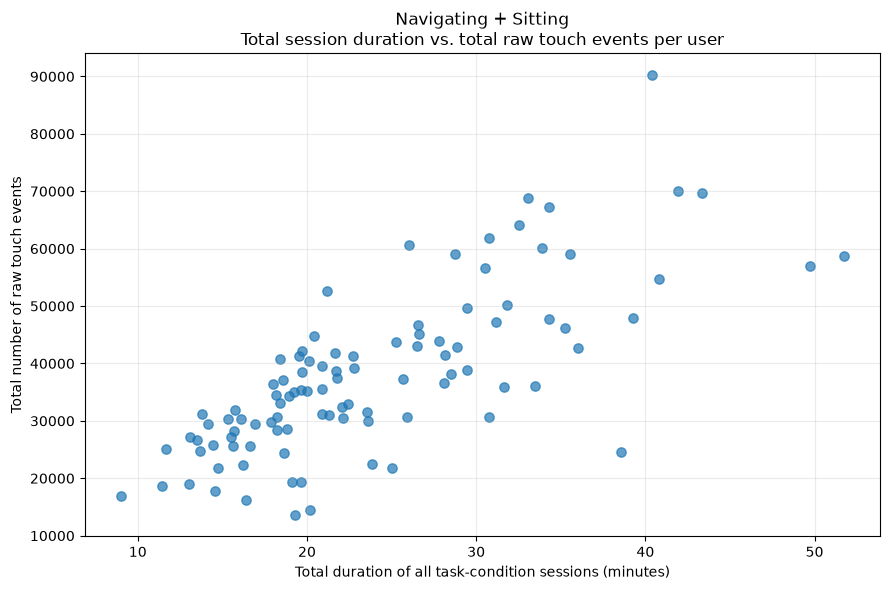

navigating + sitting: 100 users, Pearson correlation = 0.744


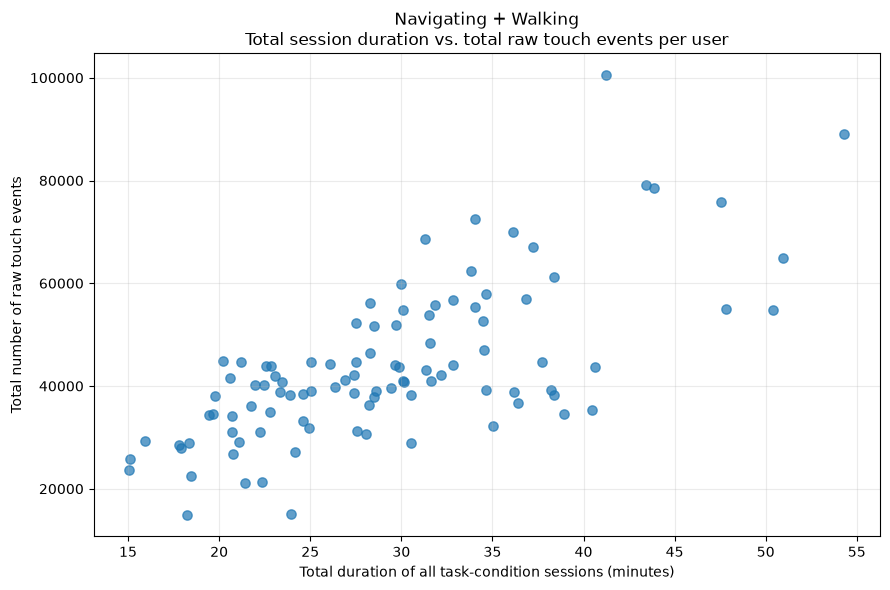

navigating + walking: 100 users, Pearson correlation = 0.700


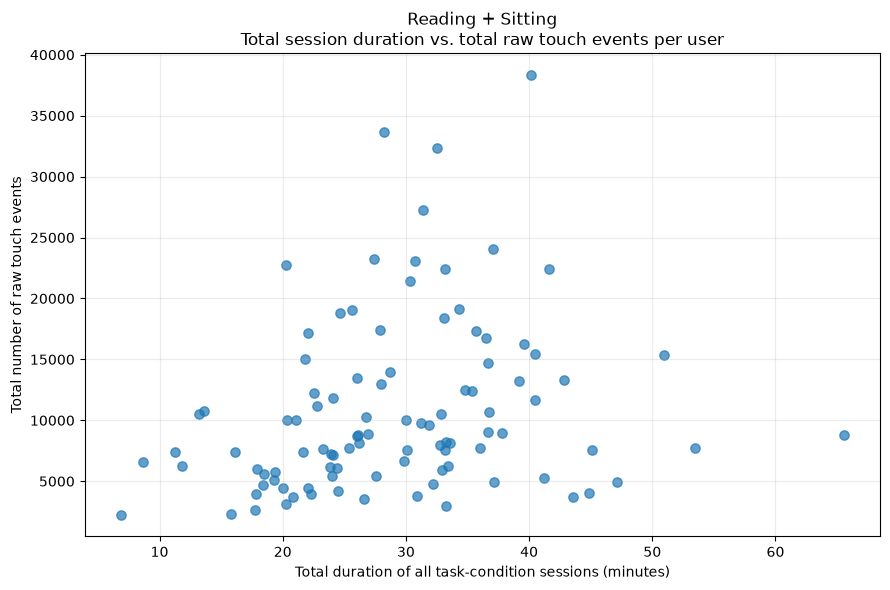

reading + sitting: 100 users, Pearson correlation = 0.233


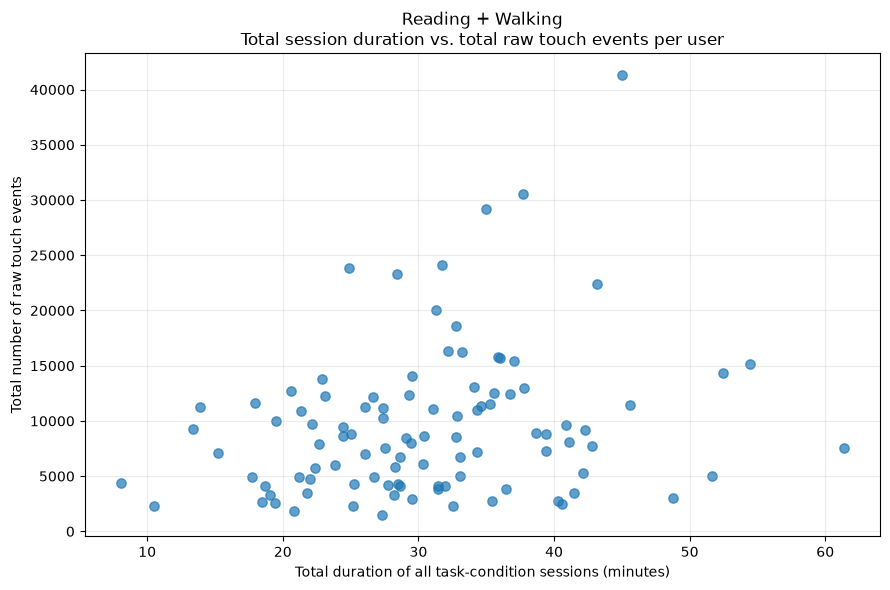

reading + walking: 100 users, Pearson correlation = 0.239


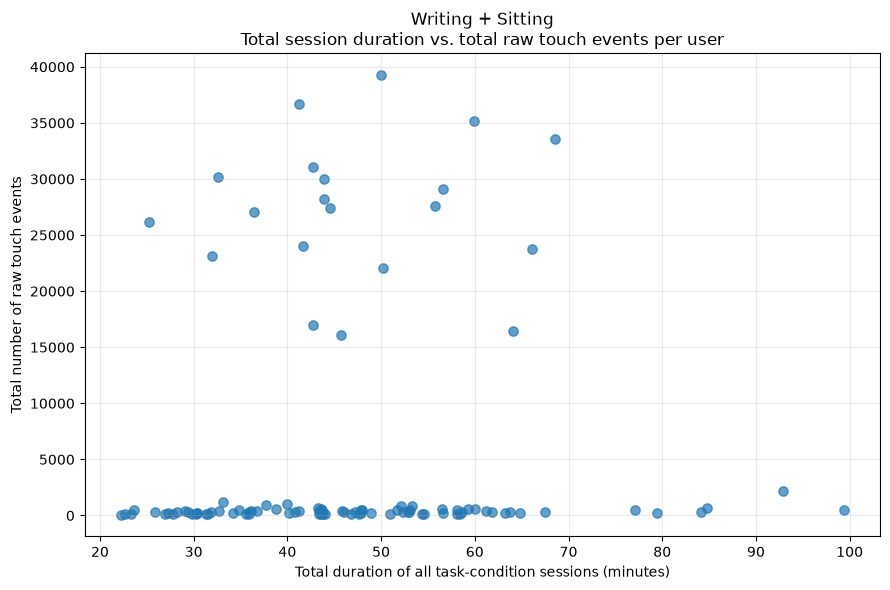

writing + sitting: 100 users, Pearson correlation = 0.028


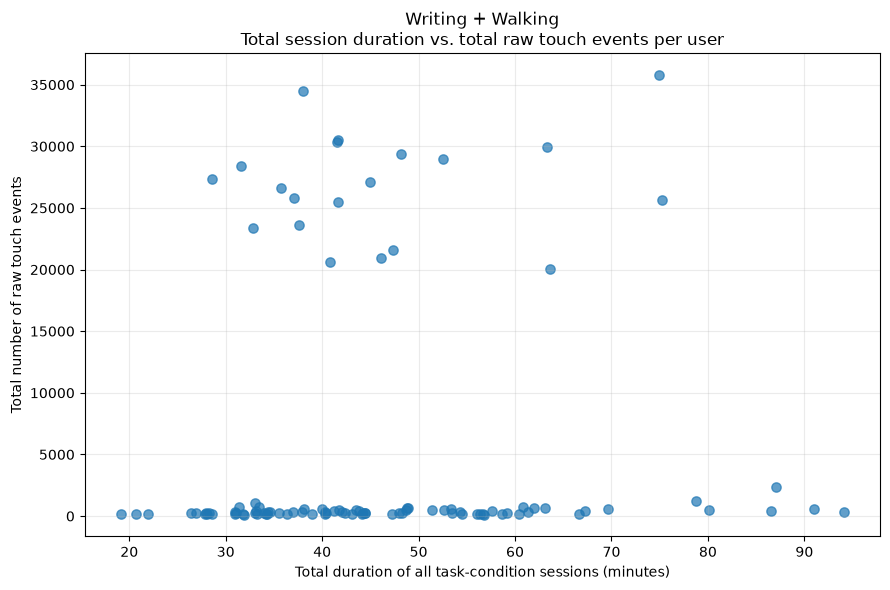

writing + walking: 100 users, Pearson correlation = 0.024


In [20]:
# Scatter plots: total session duration vs total raw touch events per user
# One separate plot for each task_condition.
#
# Each dot = one user
# X = total minutes spent in all sessions of that task_condition
# Y = total raw touch events across those sessions

import pandas as pd
import matplotlib.pyplot as plt

df = sessions.copy()

# ------------------------------------------------------------
# Create readable task-condition labels
# ------------------------------------------------------------

df["task_readable"] = (
    df["task"]
    .astype(str)
    .str.lower()
    .replace({
        "map": "navigating",
        "navigation": "navigating",
    })
)

df["condition_readable"] = (
    df["condition"]
    .astype(str)
    .str.lower()
)

df["task_condition"] = (
    df["task_readable"]
    + " + "
    + df["condition_readable"]
)


# ------------------------------------------------------------
# Aggregate ALL sessions per user + task_condition
# ------------------------------------------------------------

user_task_stats = (
    df
    .groupby(
        ["subject_id", "task_condition"],
        as_index=False
    )
    .agg(
        total_minutes=("session_span_minutes", "sum"),
        total_raw_touch_events=("raw_touch_rows", "sum"),
        n_sessions=("session_number", "count"),
    )
)


# ------------------------------------------------------------
# Inspect aggregated data
# ------------------------------------------------------------

display(
    user_task_stats.sort_values(
        ["task_condition", "subject_id"]
    )
)


# ------------------------------------------------------------
# Draw one scatter plot per task_condition
# ------------------------------------------------------------

for task_condition in sorted(
    user_task_stats["task_condition"].unique()
):

    plot_data = (
        user_task_stats[
            user_task_stats["task_condition"] == task_condition
        ]
        .sort_values("subject_id")
        .copy()
    )

    fig, ax = plt.subplots(figsize=(9, 6))

    ax.scatter(
        plot_data["total_minutes"],
        plot_data["total_raw_touch_events"],
        alpha=0.7,
        s=45,
    )

    ax.set_title(
        f"{task_condition.title()}\n"
        "Total session duration vs. total raw touch events per user"
    )

    ax.set_xlabel(
        "Total duration of all task-condition sessions (minutes)"
    )

    ax.set_ylabel(
        "Total number of raw touch events"
    )

    ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()


    # Optional numerical information
    correlation = plot_data[
        ["total_minutes", "total_raw_touch_events"]
    ].corr().iloc[0, 1]

    print(
        f"{task_condition}: "
        f"{len(plot_data)} users, "
        f"Pearson correlation = {correlation:.3f}"
    )

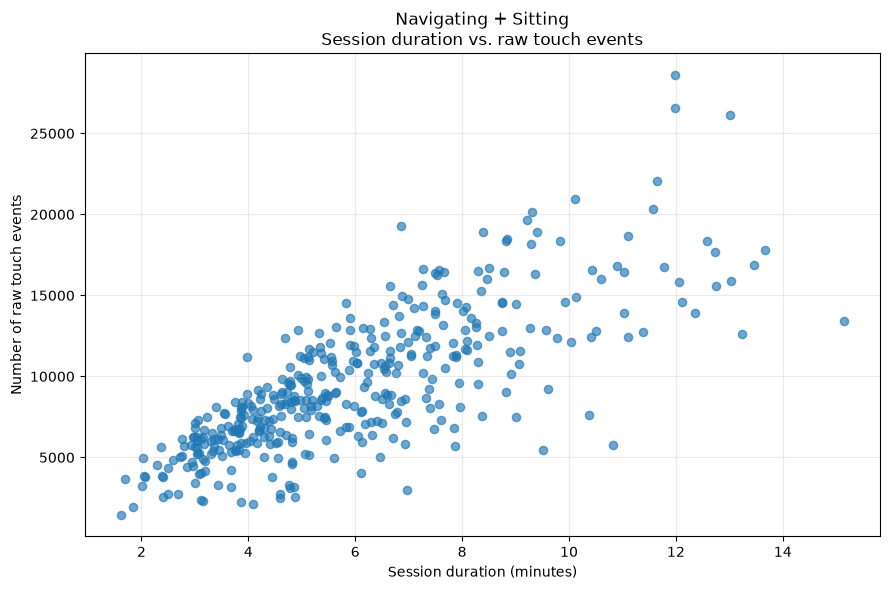

navigating + sitting: 400 sessions, Pearson correlation = 0.772


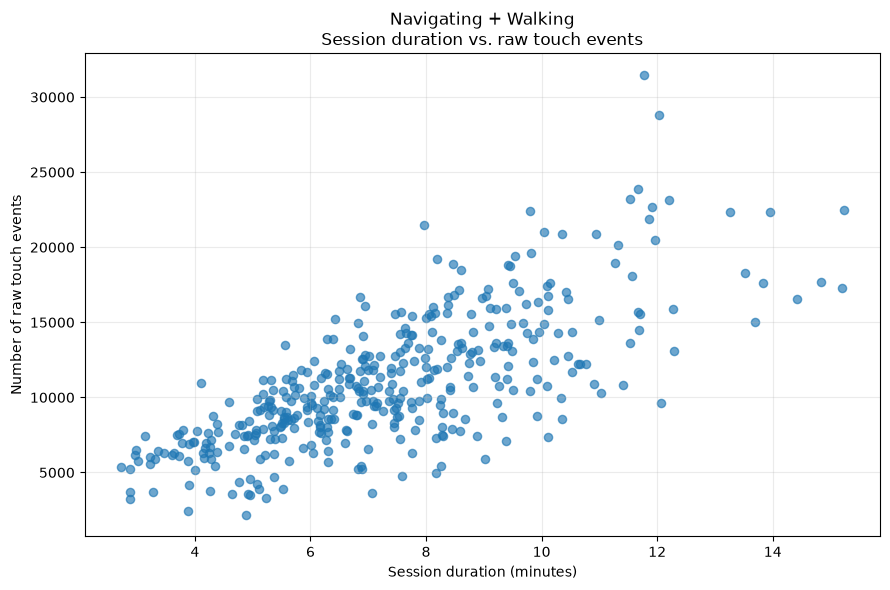

navigating + walking: 399 sessions, Pearson correlation = 0.733


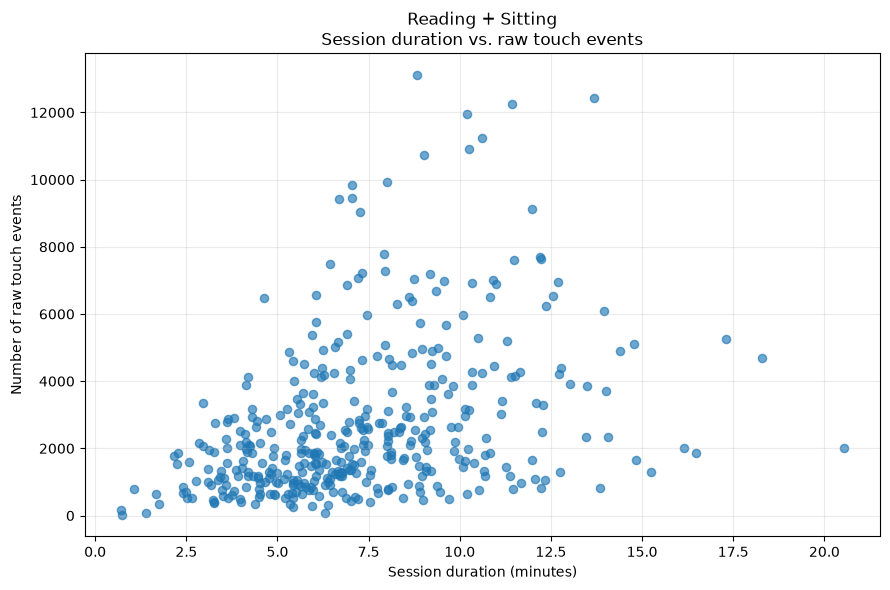

reading + sitting: 399 sessions, Pearson correlation = 0.372


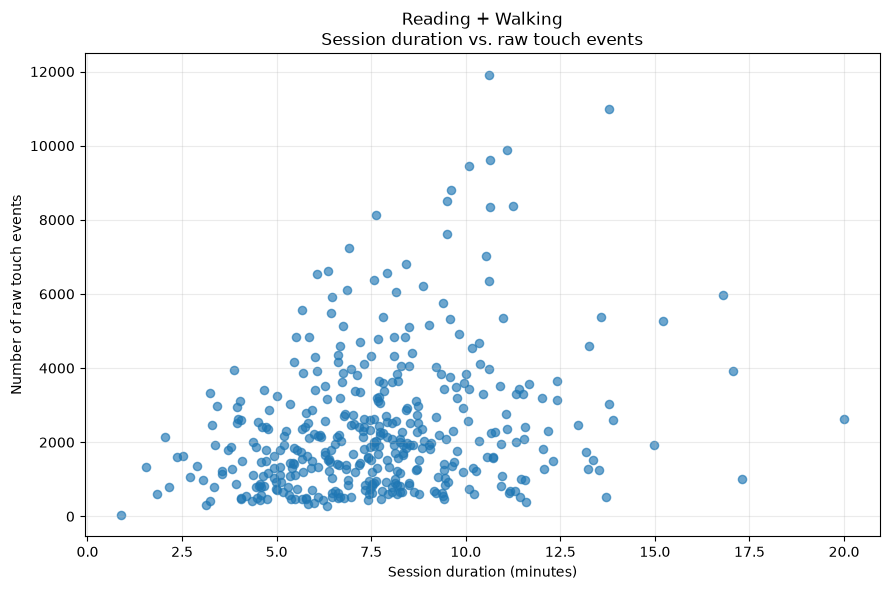

reading + walking: 400 sessions, Pearson correlation = 0.273


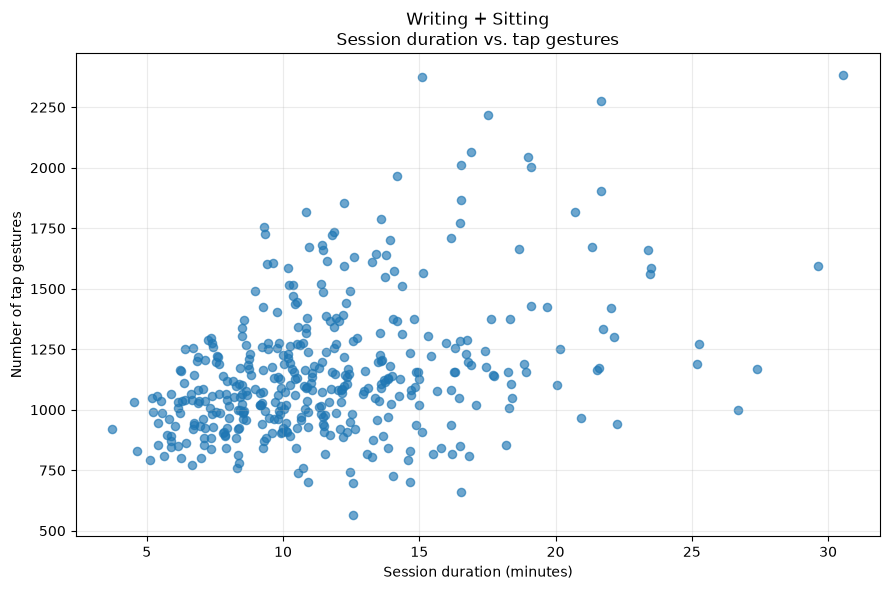

writing + sitting: 400 sessions, Pearson correlation = 0.391


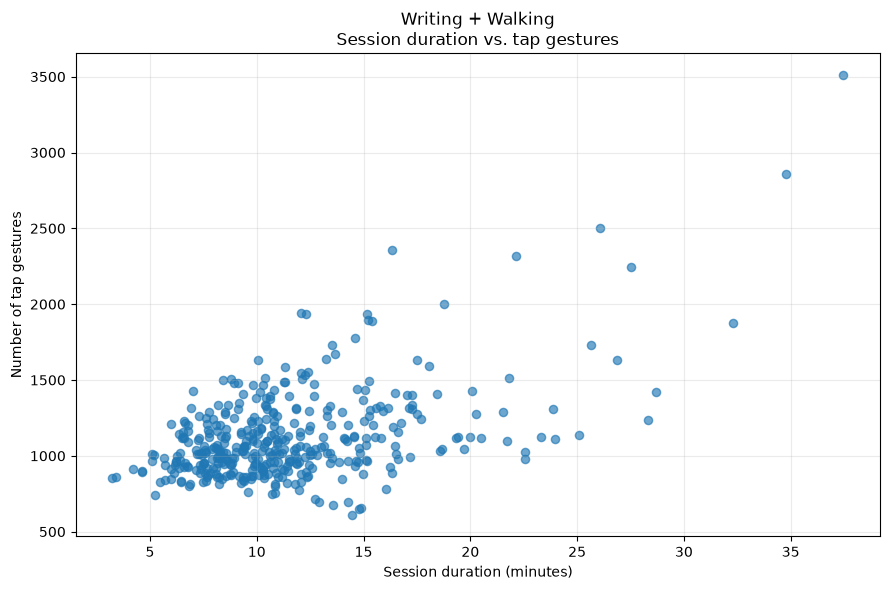

writing + walking: 400 sessions, Pearson correlation = 0.524


In [22]:
# Scatter plots per task_condition
#
# One dot = one session
#
# X = session duration in minutes
#
# Y =
#   - writing sessions: number of logical tap gestures
#   - reading/navigating sessions: number of raw touch events

import pandas as pd
import matplotlib.pyplot as plt

df = sessions.copy()

# ------------------------------------------------------------
# Create readable task-condition labels
# ------------------------------------------------------------

df["task_readable"] = (
    df["task"]
    .astype(str)
    .str.lower()
    .replace({
        "map": "navigating",
        "navigation": "navigating",
    })
)

df["condition_readable"] = (
    df["condition"]
    .astype(str)
    .str.lower()
)

df["task_condition"] = (
    df["task_readable"]
    + " + "
    + df["condition_readable"]
)


# ------------------------------------------------------------
# Plot one graph per task_condition
# ------------------------------------------------------------

for task_condition in sorted(df["task_condition"].unique()):

    plot_data = (
        df[
            df["task_condition"] == task_condition
        ]
        .sort_values(["subject_id", "session_number"])
        .copy()
    )

    # Use taps for writing; raw touch events otherwise
    if task_condition.startswith("writing"):
        y_column = "distinct_taps"
        y_label = "Number of tap gestures"
        metric_name = "tap gestures"
    else:
        y_column = "raw_touch_rows"
        y_label = "Number of raw touch events"
        metric_name = "raw touch events"

    fig, ax = plt.subplots(figsize=(9, 6))

    ax.scatter(
        plot_data["session_span_minutes"],
        plot_data[y_column],
        alpha=0.65,
        s=35,
    )

    ax.set_title(
        f"{task_condition.title()}\n"
        f"Session duration vs. {metric_name}"
    )

    ax.set_xlabel("Session duration (minutes)")
    ax.set_ylabel(y_label)

    ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

    # Pearson correlation
    correlation = plot_data[
        ["session_span_minutes", y_column]
    ].corr().iloc[0, 1]

    print(
        f"{task_condition}: "
        f"{len(plot_data)} sessions, "
        f"Pearson correlation = {correlation:.3f}"
    )

In [4]:
# Total number of logical gestures produced during ALL reading sessions
# across all users and both sitting/walking conditions.

import pandas as pd

reading = sessions[
    sessions["task"].astype(str).str.lower().eq("reading")
].copy()

gesture_columns = {
    "Taps": "distinct_taps",
    "Pinches": "distinct_pinches",
    "Scrolls": "distinct_scrolls",
    "Strokes / flings": "stroke_gesture_rows",
    "Keystrokes": "key_down_events",
}

# Make sure the required columns exist
missing = [
    col for col in gesture_columns.values()
    if col not in reading.columns
]

if missing:
    raise KeyError(
        f"Missing columns in sessions DataFrame: {missing}"
    )

# Convert safely to numeric
for col in gesture_columns.values():
    reading[col] = pd.to_numeric(
        reading[col],
        errors="coerce"
    ).fillna(0)

# Total per gesture type
gesture_totals = pd.Series({
    gesture_name: int(reading[column].sum())
    for gesture_name, column in gesture_columns.items()
})

# Grand total
grand_total = int(gesture_totals.sum())

print(f"Reading sessions: {len(reading):,}")
print(f"Users represented: {reading['subject_id'].nunique():,}")
print()

display(
    gesture_totals
    .rename("total")
    .to_frame()
)

print(f"TOTAL LOGICAL GESTURES DURING ALL READING TASKS: {grand_total:,}")

Reading sessions: 799
Users represented: 100



,total
Taps,5795
Pinches,129
Scrolls,41182
Strokes / flings,23435
Keystrokes,0


TOTAL LOGICAL GESTURES DURING ALL READING TASKS: 70,541


In [5]:
# Total number of logical gestures produced during ALL writing sessions
# across all users and both sitting/walking conditions.

import pandas as pd

writing = sessions[
    sessions["task"].astype(str).str.lower().eq("writing")
].copy()

gesture_columns = {
    "Taps": "distinct_taps",
    "Pinches": "distinct_pinches",
    "Scrolls": "distinct_scrolls",
    "Strokes / flings": "stroke_gesture_rows",
    "Keystrokes": "key_down_events",
}

# Verify required columns
missing = [
    col for col in gesture_columns.values()
    if col not in writing.columns
]

if missing:
    raise KeyError(
        f"Missing columns in sessions DataFrame: {missing}"
    )

# Convert safely to numeric
for col in gesture_columns.values():
    writing[col] = pd.to_numeric(
        writing[col],
        errors="coerce"
    ).fillna(0)

# Total per gesture type
gesture_totals_writing = pd.Series({
    gesture_name: int(writing[column].sum())
    for gesture_name, column in gesture_columns.items()
})

# Grand total
grand_total_writing = int(gesture_totals_writing.sum())

print(f"Writing sessions: {len(writing):,}")
print(f"Users represented: {writing['subject_id'].nunique():,}")
print()

display(
    gesture_totals_writing
    .rename("total")
    .to_frame()
)

print(
    f"TOTAL LOGICAL GESTURE / KEY EVENTS DURING ALL WRITING TASKS: "
    f"{grand_total_writing:,}"
)

Writing sessions: 800
Users represented: 100



,total
Taps,911755
Pinches,6
Scrolls,0
Strokes / flings,19793
Keystrokes,718306


TOTAL LOGICAL GESTURE / KEY EVENTS DURING ALL WRITING TASKS: 1,649,860


In [9]:
# Find all HMOG sessions containing at least one landscape-orientation row.
#
# Landscape:
#   Phone_orientation == 1  -> rotated 90° counter-clockwise
#   Phone_orientation == 3  -> rotated 90° clockwise
#
# For every affected session, calculate:
#   landscape_percentage =
#       landscape rows / all rows with orientation data * 100
#
# IMPORTANT:
# The denominator includes ALL rows from orientation-bearing data streams:
# accelerometer, gyroscope, magnetometer, raw touch, key press,
# one-finger touch/taps, pinch, scroll, and stroke/fling.

import pandas as pd
from pathlib import Path

# Load helper if it is not already loaded
if "hmog" not in globals():
    hmog = load_hmog_helper(HELPER_SCRIPT)

# Discover all raw HMOG session directories
discovered = hmog.discover_sessions(DATA_ROOT)

# These are the streams for which Phone_orientation is recorded
ORIENTATION_STREAMS = [
    "accelerometer",
    "gyroscope",
    "magnetometer",
    "touch_event",
    "key_press_event",
    "one_finger_touch_event",
    "pinch_event",
    "scroll_event",
    "stroke_event",
]

LANDSCAPE_VALUES = {1, 3}

results = []

for _, discovered_row in discovered.iterrows():

    session_dir = Path(discovered_row["session_dir"])

    # Load all CSVs from this session
    raw = hmog.load_session_data(session_dir)

    # --------------------------------------------------------
    # Identify subject/session metadata from Activity.csv
    # --------------------------------------------------------

    activity = raw.get("activity")

    if activity is None or activity.empty:
        print(f"Skipping session with missing Activity.csv: {session_dir}")
        continue

    # Subject/session info may already exist in discover_sessions()
    subject_id = discovered_row.get("subject_id", None)
    session_number = discovered_row.get("session_number", None)

    # Fall back to Activity.csv if necessary
    if pd.isna(subject_id) if subject_id is not None else True:
        if "SubjectID" in activity.columns:
            subject_id = activity["SubjectID"].iloc[0]

    if pd.isna(session_number) if session_number is not None else True:
        if "Session_number" in activity.columns:
            session_number = activity["Session_number"].iloc[0]

    # --------------------------------------------------------
    # Determine task + condition from the existing sessions DF
    # --------------------------------------------------------

    task = None
    condition = None

    if (
        subject_id is not None
        and session_number is not None
        and "sessions" in globals()
    ):
        match = sessions[
            (sessions["subject_id"].astype(str) == str(subject_id))
            &
            (sessions["session_number"].astype(int) == int(session_number))
        ]

        if not match.empty:
            task = match.iloc[0]["task"]
            condition = match.iloc[0]["condition"]

    # --------------------------------------------------------
    # Count orientation-bearing rows
    # --------------------------------------------------------

    total_rows = 0
    landscape_rows = 0

    per_stream = {}

    for stream_name in ORIENTATION_STREAMS:

        df_stream = raw.get(stream_name)

        if df_stream is None or df_stream.empty:
            per_stream[stream_name] = {
                "total": 0,
                "landscape": 0,
            }
            continue

        if "Phone_orientation" not in df_stream.columns:
            per_stream[stream_name] = {
                "total": 0,
                "landscape": 0,
            }
            continue

        orientation = pd.to_numeric(
            df_stream["Phone_orientation"],
            errors="coerce"
        )

        # Only rows with a valid orientation value belong in denominator
        valid = orientation.notna()

        stream_total = int(valid.sum())

        stream_landscape = int(
            (
                valid
                &
                orientation.isin(LANDSCAPE_VALUES)
            ).sum()
        )

        total_rows += stream_total
        landscape_rows += stream_landscape

        per_stream[stream_name] = {
            "total": stream_total,
            "landscape": stream_landscape,
        }

    # Keep only sessions where landscape occurred at least once
    if landscape_rows == 0:
        continue

    percentage = (
        100.0 * landscape_rows / total_rows
        if total_rows > 0
        else 0.0
    )

    results.append({
        "subject_id": subject_id,
        "session_number": session_number,
        "task": task,
        "condition": condition,
        "total_rows": total_rows,
        "landscape_rows": landscape_rows,
        "landscape_percentage": percentage,

        # Optional diagnostic columns
        "accelerometer_landscape": per_stream["accelerometer"]["landscape"],
        "gyroscope_landscape": per_stream["gyroscope"]["landscape"],
        "magnetometer_landscape": per_stream["magnetometer"]["landscape"],
        "touch_landscape": per_stream["touch_event"]["landscape"],
        "key_press_landscape": per_stream["key_press_event"]["landscape"],
        "tap_landscape": per_stream["one_finger_touch_event"]["landscape"],
        "pinch_landscape": per_stream["pinch_event"]["landscape"],
        "scroll_landscape": per_stream["scroll_event"]["landscape"],
        "stroke_landscape": per_stream["stroke_event"]["landscape"],
    })


# ------------------------------------------------------------
# Final table
# ------------------------------------------------------------

landscape_sessions = pd.DataFrame(results)

if landscape_sessions.empty:
    print("No sessions with landscape-orientation data were found.")

else:
    landscape_sessions = (
        landscape_sessions
        .sort_values(["subject_id", "session_number"])
        .reset_index(drop=True)
    )

    landscape_sessions["landscape_percentage"] = (
        landscape_sessions["landscape_percentage"].round(3)
    )

    print(
        f"Sessions containing landscape data: "
        f"{len(landscape_sessions):,}"
    )

    print(
        f"Users with at least one such session: "
        f"{landscape_sessions['subject_id'].nunique():,}"
    )

    display(
        landscape_sessions[
            [
                "subject_id",
                "session_number",
                "task",
                "condition",
                "landscape_rows",
                "total_rows",
                "landscape_percentage",
            ]
        ]
    )

Sessions containing landscape data: 387
Users with at least one such session: 80


,subject_id,session_number,task,condition,landscape_rows,total_rows,landscape_percentage
0,100669,1,reading,sitting,1083,242774,0.446
1,151985,2,reading,sitting,183,269363,0.068
2,151985,9,writing,sitting,398,255937,0.156
3,151985,18,reading,walking,198,206823,0.096
4,186676,1,writing,walking,617,192316,0.321
...,...,...,...,...,...,...,...
382,998757,11,writing,walking,273365,280017,97.624
383,998757,14,reading,walking,452,118135,0.383
384,998757,15,writing,sitting,243164,257256,94.522
385,998757,16,writing,walking,228970,250581,91.376


In [10]:
landscape_sessions.to_csv("landscape_sessions.csv")